<a href="https://colab.research.google.com/github/Pawanithalagala/sp500-stock-marketanalysis/blob/main/6BUIS017W_CRM_%26_CM_With_BI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, io, json, time, platform, datetime as dt
import requests
import pandas as pd, numpy as np
import yfinance as yf
from importlib.metadata import version

In [2]:
packages = ["pandas", "numpy", "yfinance", "requests",
            "lxml", "scikit-learn", "matplotlib", "seaborn"]

print("Python version:", platform.python_version())

with open("requirements.txt", "w") as f:
    for package in packages:
        f.write(f"{package}=={version(package)}\n")

Python version: 3.13.18


In [3]:
!pip -q install yfinance lxml

# **Task 1 Data Preparation and Feature Engineering**

**Task 1.1 Ticker selection and data acquisition**

In [4]:
START, END = "2021-01-01", "2025-01-01"
BENCH      = "^GSPC"                         # S&P 500 benchmark
WIKI_URL   = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
DATA_DIR, OUT_DIR = "data", "outputs"
REFRESH    = True                            # True = try a live download, False = reuse saved files in data
BATCH      = 100
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Ticker list from Wikipedia (pandas) + retrieval date
def get_constituents():
    html = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
    with open(f"{DATA_DIR}/wikipedia_sp500_page.html", "w", encoding="utf-8") as f:
        f.write(html)                                            # keep the raw page as evidence

    table = pd.read_html(io.StringIO(html))[0]
    c = table[["Symbol", "Security", "GICS Sector", "GICS Sub-Industry", "Date added"]].copy()
    c["Ticker"] = c["Symbol"].str.replace(".", "-", regex=False)  # Yahoo format: BRK.B to BRK-B
    c["retrieval_utc"] = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
    c["retrieval_date"] = dt.date.today().isoformat()
    c["source_url"] = WIKI_URL
    c.to_csv(f"{DATA_DIR}/sp500_constituents.csv", index=False)
    return c

# Download Close, Adj Close and Volume for all shares + benchmark
def download_prices(tickers):
    frames = []
    failed = []
    for i in range(0, len(tickers), BATCH):
        chunk = tickers[i:i + BATCH]
        for attempt in range(3):
            try:
                r = yf.download(chunk, start=START, end=END, auto_adjust=False, progress=False)
                if not r.empty:
                    frames.append(r)
                    break
            except Exception as e:
                print("Batch", i // BATCH, "attempt", attempt + 1, "failed:", e)
            time.sleep(2)
        else:
            failed += chunk

    raw = pd.concat(frames, axis=1)
    raw = raw.loc[:, ~raw.columns.duplicated()]

    # Save raw snapshots before any cleaning
    raw["Close"].to_csv(f"{DATA_DIR}/daily_prices.csv")
    raw["Adj Close"].to_csv(f"{DATA_DIR}/adjusted_prices.csv")
    raw["Volume"].to_csv(f"{DATA_DIR}/volume.csv")
    return failed

live_ok = False
failed_batches = []
if REFRESH:
    try:
        cons = get_constituents()
        failed_batches = download_prices(cons["Ticker"].tolist() + [BENCH])
        live_ok = True
        print("Live download completed.")
    except Exception as e:
        print("Live download failed, using saved snapshots:", e)

# Load the saved files
cons  = pd.read_csv(f"{DATA_DIR}/sp500_constituents.csv")
close = pd.read_csv(f"{DATA_DIR}/daily_prices.csv",    index_col=0, parse_dates=True)
adj   = pd.read_csv(f"{DATA_DIR}/adjusted_prices.csv", index_col=0, parse_dates=True)
vol   = pd.read_csv(f"{DATA_DIR}/volume.csv",          index_col=0, parse_dates=True)

# Acquisition checks
tick = cons["Ticker"].tolist()
n_sessions = int(adj[BENCH].notna().sum())                        # benchmark trading days
coverage = adj.drop(columns=[BENCH]).notna().sum()                # valid days per share

print("Retrieval date:", cons["retrieval_date"].iloc[0])
print("Tickers listed:", len(tick), "| duplicates:", pd.Series(tick).duplicated().sum())
print("Shares in download:", sum(t in adj.columns for t in tick))
print("Benchmark present:", BENCH in adj.columns, "| sessions:", n_sessions)
print("Period:", adj.index.min().date(), "to", adj.index.max().date(), "(end date exclusive)")
print("Shares with full history:", int((coverage == n_sessions).sum()))
print("Shares with partial history:", int(((coverage > 0) & (coverage < n_sessions)).sum()))
print("Shares with no data:", int((coverage == 0).sum()))

# Survivorship bias evidence
added = pd.to_datetime(cons["Date added"], errors="coerce")
late = cons.loc[added > pd.Timestamp(START), ["Ticker", "Security", "Date added"]]
print("\nCurrent members added after", START, ":", len(late), "of", len(cons))
late.to_csv(f"{DATA_DIR}/constituents_added_after_start.csv", index=False)

# Save a manifest
manifest = {
    "study_start": START,
    "study_end_exclusive": END,
    "benchmark": BENCH,
    "price_fields": "auto_adjust=False; Close, Adj Close and Volume saved",
    "why_yfinance": "gives adjusted prices and volume, no API key needed; unofficial (limitation)",
    "live_download_this_run": live_ok,
    "failed_batches": failed_batches,
    }
with open(f"{DATA_DIR}/acquisition_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)

# Display
raw_data = cons

print("\nFirst five rows:")
display(raw_data.head())

print("\nLast five rows:")
display(raw_data.tail())

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['VYLR', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Live download completed.
Retrieval date: 2026-11-24
Tickers listed: 503 | duplicates: 0
Shares in download: 503
Benchmark present: True | sessions: 1005
Period: 2021-01-04 to 2024-12-31 (end date exclusive)
Shares with full history: 488
Shares with partial history: 10
Shares with no data: 5

Current members added after 2021-01-01 : 89 of 503

First five rows:


,Symbol,Security,GICS Sector,GICS Sub-Industry,Date added,Ticker,retrieval_utc,retrieval_date,source_url
0,MMM,3M,Industrials,Industrial Conglomerates,1957-03-04,MMM,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
1,AOS,A. O. Smith,Industrials,Building Products,2017-07-26,AOS,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,1957-03-04,ABT,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
3,ABBV,AbbVie,Health Care,Biotechnology,2012-12-31,ABBV,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,2011-07-06,ACN,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...



Last five rows:


,Symbol,Security,GICS Sector,GICS Sub-Industry,Date added,Ticker,retrieval_utc,retrieval_date,source_url
498,XYL,Xylem Inc.,Industrials,Industrial Machinery & Supplies & Components,2011-11-01,XYL,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
499,YUM,Yum! Brands,Consumer Discretionary,Restaurants,1997-10-06,YUM,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
500,ZBRA,Zebra Technologies,Information Technology,Electronic Equipment & Instruments,2019-12-23,ZBRA,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
501,ZBH,Zimmer Biomet,Health Care,Health Care Equipment,2001-08-07,ZBH,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...
502,ZTS,Zoetis,Health Care,Pharmaceuticals,2013-06-21,ZTS,2026-11-24T19:58:29+00:00,2026-11-24,https://en.wikipedia.org/wiki/List_of_S%26P_50...


**1.2 Data validation and alignment**

In [5]:
# Load the snapshots saved
cons  = pd.read_csv(f"{DATA_DIR}/sp500_constituents.csv")
close = pd.read_csv(f"{DATA_DIR}/daily_prices.csv",    index_col=0, parse_dates=True)
adj   = pd.read_csv(f"{DATA_DIR}/adjusted_prices.csv", index_col=0, parse_dates=True)
vol   = pd.read_csv(f"{DATA_DIR}/volume.csv",          index_col=0, parse_dates=True)
with open(f"{DATA_DIR}/acquisition_manifest.json") as f:
    man = json.load(f)

# The S&P 500 benchmark's trading days are used as the calendar
cal = adj[BENCH].dropna().index
shares = [t for t in cons["Ticker"] if t in adj.columns]

print("Before cleaning (dates, shares):", (len(cal), len(shares)), "| plus benchmark", BENCH)
print("Data source: live download =", man["live_download_this_run"])
print("Period covered:", cal.min().date(), "to", cal.max().date(), "|", len(cal), "benchmark sessions")

# Duplicate dates and date order
print("\nDuplicate dates (adj, close, vol):",
      adj.index.duplicated().sum(), close.index.duplicated().sum(), vol.index.duplicated().sum())
print("Dates sorted:", adj.index.is_monotonic_increasing)
print("Weekend dates:", (adj.index.dayofweek >= 5).sum())

# Missing values and unequal histories
print("\nMissing values in each panel (shares only):")
for name, d in {"Close": close, "Adj Close": adj, "Volume": vol}.items():
    print(name, "| null cells:", int(d[shares].isna().sum().sum()),
          "| shares with any null:", int((d[shares].isna().sum() > 0).sum()))

first_valid = adj[shares].apply(lambda s: s.first_valid_index())
print("Shares starting after the first benchmark date:", int((first_valid > cal.min()).sum()))
print("Latest listings:\n", first_valid[first_valid > cal.min()].sort_values().tail(5))

# Invalid prices and volumes
print("\nNon-positive price cells:", int((adj[shares] <= 0).sum().sum() + (close[shares] <= 0).sum().sum()))
print("Negative volume cells:", int((vol[shares] < 0).sum().sum()))
print("Zero volume cells:", int((vol[shares] == 0).sum().sum()),
      "| shares affected:", int((vol[shares] == 0).any().sum()))

# Retention rules - one log row per share
rows = []
for t in cons["Ticker"]:
    reason = ""
    if t not in adj.columns:
        reason = "no data returned by Yahoo Finance"
    else:
        a = adj[t].reindex(cal)
        c = close[t].reindex(cal)
        v = vol[t].reindex(cal)
        n_missing = max(a.isna().sum(), c.isna().sum(), v.isna().sum())

        if a.isna().all():
            reason = "all prices missing"
        elif n_missing > 0:
            reason = f"missing data on {n_missing} dates (late listing or gaps)"
        elif (a <= 0).any() or (c <= 0).any():
            reason = "non-positive price"
        elif (v < 0).any():
            reason = "negative volume"
        elif (v == 0).any():
            reason = f"zero-volume days ({int((v == 0).sum())})"
    rows.append((t, reason == "", reason))

log = pd.DataFrame(rows, columns=["Ticker", "retained", "exclusion_reason"]).set_index("Ticker")
keep = log.index[log["retained"]].tolist()

print("\nAfter cleaning (dates, shares):", (len(cal), len(keep)))
print("Shares removed:", len(log) - len(keep), "of", len(log))
print("\nExclusion reasons:")
print(log.loc[~log["retained"], "exclusion_reason"].str.replace(r"\d+", "N", regex=True).value_counts())

# Check that the retained data really has no gaps
assert adj[keep].loc[cal].notna().all().all()
assert close[keep].loc[cal].notna().all().all()
assert vol[keep].loc[cal].notna().all().all()

# Corporate actions (splits and dividends)
# Close = split-adjusted only, Adj Close = split + dividend adjusted
c_ret = close[keep].pct_change(fill_method=None)
a_ret = adj[keep].pct_change(fill_method=None)

gaps = ((c_ret - a_ret).abs() > 0.02).any().sum()
print("\nShares where Close and Adj Close returns differ by more than 2% (dividends):", int(gaps))

# Review daily Close moves above 40%: a split would show a ratio like 0.5, 0.25 or 2, 3, 4
vol_ratio = vol[keep] / vol[keep].shift(1).rolling(20).mean()
review = []
for t in keep:
    for d in c_ret.index[c_ret[t].abs() > 0.40]:
        ratio = 1 + c_ret.at[d, t]
        split_like = any(abs(ratio - r) / r < 0.05 for r in (0.5, 1/3, 0.25, 0.2, 0.1, 2, 3, 4, 5, 10))
        same = abs(c_ret.at[d, t] - a_ret.at[d, t]) < 0.02
        if same and vol_ratio.at[d, t] >= 2 and not split_like:
            decision = "retain: genuine price shock"
        else:
            decision = "MANUAL REVIEW"
        review.append([t, d.date(), round(c_ret.at[d, t], 3), round(vol_ratio.at[d, t], 1), decision])

review = pd.DataFrame(review, columns=["Ticker", "Date", "Close_return", "Volume_vs_20d_mean", "Decision"])
review.to_csv(f"{OUT_DIR}/corporate_action_review.csv", index=False)
print("Daily Close moves above 40%:")
print(review.to_string(index=False) if len(review) else "none")

# Weekly prices and matching weekly return dates
P = adj[keep + [BENCH]].loc[cal]
wk = P.resample("W-FRI").last()

print("\nWeekly prices before dropping incomplete weeks:", wk.shape)
wk = wk[(wk.index - pd.Timedelta(days=4) >= pd.Timestamp(START)) & (wk.index < pd.Timestamp(END))] # Keep only complete calendar weeks (Monday of the week >= START, Friday < END)
print("Weekly prices after dropping incomplete weeks:", wk.shape)

wret = wk.pct_change(fill_method=None).iloc[1:]
assert wret.isna().sum().sum() == 0, "missing weekly returns remain"

print("Aligned weekly returns:", len(wret), "| first week:", wret.index.min().date(),
      "| last week:", wret.index.max().date())
print("Holiday-shortened weeks kept:", int((P[BENCH].resample("W-FRI").count().reindex(wk.index) < 5).sum()))

# Survivorship check
added = pd.to_datetime(cons["Date added"].astype(str).str.extract(r"(\d{4}-\d{2}-\d{2})")[0], errors="coerce")
late = cons.loc[added > pd.Timestamp(START), "Ticker"]
print("\nCurrent members that joined after", START, ":", len(late), "of", len(cons))
print("Of these, retained:", int(late.isin(keep).sum()))


# Save outputs
log.reset_index().to_csv(f"{DATA_DIR}/final_inclusion_exclusion_log.csv", index=False)
pd.Series(keep, name="Ticker").to_csv(f"{DATA_DIR}/final_tickers.csv", index=False)
wk.to_csv(f"{DATA_DIR}/weekly_adj_prices.csv")
wret.to_csv(f"{DATA_DIR}/weekly_returns.csv")

man["task_1_2"] = {"week_rule": "W-FRI last adj close; incomplete first/final weeks dropped; holiday weeks kept",
                   "aligned_weekly_obs": len(wret), "final_shares": len(keep)}
with open(f"{DATA_DIR}/acquisition_manifest.json", "w") as f:
    json.dump(man, f, indent=2, default=str)

print("\nFinal share count for Task 1.3:", len(keep), "| aligned weekly returns:", len(wret))

Before cleaning (dates, shares): (1005, 503) | plus benchmark ^GSPC
Data source: live download = True
Period covered: 2021-01-04 to 2024-12-31 | 1005 benchmark sessions

Duplicate dates (adj, close, vol): 0 0 0
Dates sorted: True
Weekend dates: 0

Missing values in each panel (shares only):
Close | null cells: 9211 | shares with any null: 15
Adj Close | null cells: 9211 | shares with any null: 15
Volume | null cells: 9211 | shares with any null: 15
Shares starting after the first benchmark date: 10
Latest listings:
 GEHC   2022-12-15
VLTO   2023-10-04
RDDT   2024-03-21
SOLV   2024-03-26
GEV    2024-03-27
dtype: datetime64[ns]

Non-positive price cells: 0
Negative volume cells: 0
Zero volume cells: 451 | shares affected: 2

After cleaning (dates, shares): (1005, 486)
Shares removed: 17 of 503

Exclusion reasons:
exclusion_reason
missing data on N dates (late listing or gaps)    10
all prices missing                                 5
zero-volume days (N)                               2
N

**1.3 Weekly return and weekly beta**

In [6]:
# 1.3 Mean weekly return and weekly beta (needs keep, wk, wret, BENCH from 1.2)
bench, ret = wret[BENCH], wret[keep]
N = len(wret)

# 1.3.1 mean weekly return: arithmetic mean of Friday-ending weekly adjusted-close returns, full period
mean_ret = ret.mean()
geo_ret = (1 + ret).prod() ** (1 / N) - 1  # compounded equivalent, to show the limitation of the arithmetic mean

# 1.3.2 weekly beta = cov(share, benchmark) / var(benchmark), sample statistics on the same N matched weeks
beta = ret.apply(lambda s: s.cov(bench)) / bench.var()
se = np.sqrt(((ret.sub(ret.mean()) - np.outer(bench - bench.mean(), beta)) ** 2).sum() / (N - 2) / ((bench - bench.mean()) ** 2).sum())
half = N // 2                                                   # stability: first half vs second half of the period
b1 = ret.iloc[:half].apply(lambda s: s.cov(bench.iloc[:half])) / bench.iloc[:half].var()
b2 = ret.iloc[half:].apply(lambda s: s.cov(bench.iloc[half:])) / bench.iloc[half:].var()
feat13 = pd.DataFrame({"MeanWeeklyReturn": mean_ret, "GeoMeanWeeklyReturn": geo_ret, "Beta": beta, "Beta_SE": se, "N_weeks": N})
os.makedirs("outputs", exist_ok=True)
feat13.to_csv("outputs/weekly_return_beta.csv")

# independent checks
t, wk_date = keep[0], wret.index[10]; prev = wk.index[wk.index.get_loc(wk_date) - 1]
assert np.isclose(wret.loc[wk_date, t], wk.loc[wk_date, t] / wk.loc[prev, t] - 1)
assert all(np.isclose(beta[s], np.polyfit(bench, ret[s], 1)[0]) for s in keep[:5])
assert np.isclose(bench.cov(bench) / bench.var(), 1) and ret.notna().all().all() and ret.shape[0] == N
adj_gap = ((close[keep].pct_change(fill_method=None) - adj[keep].pct_change(fill_method=None)).abs() > 0.02).any().sum()

print(f"Weekly returns: Friday-ending adjusted closes, {wret.index[0].date()} to {wret.index[-1].date()}, N = {N} per share and benchmark")
print(f"Mean weekly return: median {mean_ret.median():.4%}, range {mean_ret.min():.4%} to {mean_ret.max():.4%} | median arithmetic-minus-geometric gap {(mean_ret - geo_ret).median():.4%}")
print(f"Adjusted price basis used because {adj_gap} shares have dividend/adjustment gaps between Close and Adj Close; benchmark ^GSPC is a price index")

print(f"Median beta: {beta.median():.2f}")
print(f"Minimum beta: {beta.min():.2f}")
print(f"Maximum beta: {beta.max():.2f}")
print(f"Median beta standard error: {se.median():.3f}")
print(f"Approximate 95% interval: +/-{1.96 * se.median():.2f}")

print(f"Number of shares with beta below 0: {(beta < 0).sum()}")
print(f"Number of shares with beta above 2: {(beta > 2).sum()}")
print(f"Median absolute difference between first- and second-half beta: {(b1 - b2).abs().median():.2f}")

print("Checks passed: hand-computed week, beta = OLS slope, benchmark beta = 1, no missing weeks.")


Weekly returns: Friday-ending adjusted closes, 2021-01-15 to 2024-12-27, N = 207 per share and benchmark
Mean weekly return: median 0.2619%, range -0.4468% to 1.7772% | median arithmetic-minus-geometric gap 0.0743%
Adjusted price basis used because 21 shares have dividend/adjustment gaps between Close and Adj Close; benchmark ^GSPC is a price index
Median beta: 0.95
Minimum beta: 0.06
Maximum beta: 3.78
Median beta standard error: 0.101
Approximate 95% interval: +/-0.20
Number of shares with beta below 0: 0
Number of shares with beta above 2: 9
Median absolute difference between first- and second-half beta: 0.21
Checks passed: hand-computed week, beta = OLS slope, benchmark beta = 1, no missing weeks.


**1.4 Adapted RFM Calculations**

In [7]:
# Observation date = last common trading date of the shares and the benchmark
OBS_DATE = adj[keep + [BENCH]].dropna(how="any").index.max()
v, c = vol.loc[:OBS_DATE, keep], close.loc[:OBS_DATE, keep]

base = v.shift(1).rolling(20).mean()  # High-volume day: volume > 2 x average volume of the previous 20 sessions
event = v > 2 * base                  # days without 20 earlier sessions count as False
win = v.index[-60:]  # Latest 60 trading sessions ending on the observation date

# 1.4.1 Recency (R)
# R = calendar days from the latest high-volume day to the observation date
last_event = event.apply(lambda s: s[s].index.max() if s.any() else pd.NaT)
last_event = pd.to_datetime(last_event)
R = (OBS_DATE - last_event).dt.days.astype(float)

# 1.4.2 Frequency (F)
# F = number of high-volume days in the latest 60 sessions
F = event.loc[win].sum()

#  1.4.3 Monetary (M)
# M = sum of daily Close x Volume over the latest 60 sessions (USD)
M = (c.loc[win] * v.loc[win]).sum()

rfm = pd.DataFrame({"last_event": last_event, "R": R, "F": F, "M": M})

# Shares with no high-volume day are excluded from RFM clustering
no_event = rfm.index[rfm["R"].isna()]
pd.DataFrame({"Ticker": no_event,
              "Reason": "no high-volume day; R missing, not set to 0"}).to_csv(f"{OUT_DIR}/no_event_exclusions.csv", index=False)
rfm.to_csv(f"{OUT_DIR}/rfm_raw.csv")

# Checks
print("Observation date:", OBS_DATE.date())
print("60-session window:", win[0].date(), "to", win[-1].date(), "| sessions:", len(win))
print("Shares with no event (R missing):", len(no_event))
print("Shares with R = 0 (event on observation date):", int((rfm["R"] == 0).sum()))
print(rfm[["R", "F", "M"]].describe().round(1))

# manual check one share
t = "AAPL" if "AAPL" in keep else keep[len(keep) // 2]
vals = v[t].values
days = [j for j in range(20, len(vals)) if vals[j] > 2 * vals[j-20:j].mean()]
assert v.index[days[-1]] == last_event[t]
assert (OBS_DATE - v.index[days[-1]]).days == R[t]
assert sum(v.index[j] in win for j in days) == F[t]
assert np.isclose(M[t], (c[t].loc[win] * v[t].loc[win]).sum())
print("Manual checks passed for", t)


# Worked RFM example for one share
example_ticker = "AAPL" if "AAPL" in keep else keep[0]

print("\nWorked RFM example:", example_ticker)
print("Observation date:", OBS_DATE.date())
print("Latest qualifying high-volume date:",
      last_event[example_ticker])

print("Recency (R):",
      rfm.loc[example_ticker, "R"], "calendar days")
print("Frequency (F):",
      rfm.loc[example_ticker, "F"], "high-volume days")
print("Monetary (M): $",
      f"{rfm.loc[example_ticker, 'M']:,.2f}")
print("M in USD billions:",
      round(rfm.loc[example_ticker, "M"] / 1e9, 3))

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31 | sessions: 60
Shares with no event (R missing): 0
Shares with R = 0 (event on observation date): 0
           R      F             M
count  486.0  486.0  4.860000e+02
mean    20.4    3.0  3.940419e+10
std     21.3    1.3  1.291388e+11
min      4.0    0.0  1.297483e+09
25%     11.0    2.0  1.019517e+10
50%     11.0    3.0  1.668382e+10
75%     14.8    4.0  3.227689e+10
max    222.0    8.0  1.847697e+12
Manual checks passed for AAPL

Worked RFM example: AAPL
Observation date: 2024-12-31
Latest qualifying high-volume date: 2024-12-20 00:00:00
Recency (R): 11.0 calendar days
Frequency (F): 2 high-volume days
Monetary (M): $ 623,303,377,706.58
M in USD billions: 623.303


**1.5 Metric interpretation and supporting evidence**

In [8]:
valid = [s for s in keep if s not in set(no_event)]
feat = pd.concat([feat13[["MeanWeeklyReturn", "Beta"]], rfm[["R", "F", "M"]]], axis=1).loc[valid]
feat["logM"] = np.log1p(feat.M)
assert feat[["MeanWeeklyReturn", "Beta", "R", "F", "M"]].notna().all().all(), "common valid set has missing values"

# Load exclusion logs to reconstruct counts
excl = pd.read_csv(f"{DATA_DIR}/final_inclusion_exclusion_log.csv")
excl = excl[~excl["retained"]]

# inclusion / exclusion log (one row per share removed, with stage and reason) + final counts
log = pd.concat([excl[["Ticker", "exclusion_reason"]].rename(columns={"exclusion_reason": "Reason"}).assign(Stage="1.2 validation"),
                 pd.DataFrame({"Ticker": no_event, "Reason": "no high-volume event; R missing (not set to 0)", "Stage": "1.4 RFM"})])[["Ticker", "Stage", "Reason"]]
log.to_csv("outputs/inclusion_exclusion_log.csv", index=False); feat.to_csv("outputs/feature_table.csv")
print(f"Shares: downloaded {len(adj.columns) - 1} | excluded {len(log)} ({log.Stage.value_counts().to_dict()}) | final common set {len(feat)}")

# checks - threshold alignment, history sufficiency, no-event handling
rng = np.random.default_rng(42)
for s in rng.choice(valid, 5, replace=False):
    for i in rng.integers(20, len(v), 3):
        prior = v[s].iloc[i - 20:i].mean()
        assert bool(event[s].iloc[i]) == (v[s].iloc[i] > 2 * prior), (s, i)
assert base.loc[win, valid].notna().all().all(), "window days lack a full 20-session baseline"
assert v.index.get_loc(win[0]) >= 20 and len(win) == 60
assert rfm.loc[no_event, "R"].isna().all() and (feat.R.notna().all())
print(f"Checks passed: threshold alignment (15 share-days), 20-session baseline available for all 60 window days "
      f"(first baseline date {v.index[20].date()}), no-event shares {len(no_event)} left missing, common valid set n = {len(feat)}.")

# feature summary (original units)
summ = feat[["MeanWeeklyReturn", "Beta", "R", "F", "M"]].agg(["mean", "median", "std", "min", "max", "skew"]).T
summ.loc["M", ["mean", "median", "std", "min", "max"]] /= 1e9; summ = summ.rename(index={"M": "M (USD bn)"})
summ.to_csv("outputs/feature_summary.csv")
print(summ.round(4))

Shares: downloaded 503 | excluded 17 ({'1.2 validation': 17}) | final common set 486
Checks passed: threshold alignment (15 share-days), 20-session baseline available for all 60 window days (first baseline date 2021-02-02), no-event shares 0 left missing, common valid set n = 486.
                     mean   median       std     min        max     skew
MeanWeeklyReturn   0.0029   0.0026    0.0027 -0.0045     0.0178   0.8675
Beta               0.9737   0.9506    0.4073  0.0555     3.7786   1.1036
R                 20.4074  11.0000   21.3424  4.0000   222.0000   3.6458
F                  2.9897   3.0000    1.3308  0.0000     8.0000   0.4247
M (USD bn)        39.4042  16.6838  129.1388  1.2975  1847.6974  11.6838


# **Task 2 Stock Segmentation and Sensitivity Analysis**

**2.1 Feature preparation**

                   skew  n |z|>3  n IQR outliers
MeanWeeklyReturn   0.86        6              15
Beta               1.10        2              10
R                  3.63       11             115
F                  0.42        5               2
M                 11.65        5              45
logM               1.08        7              13


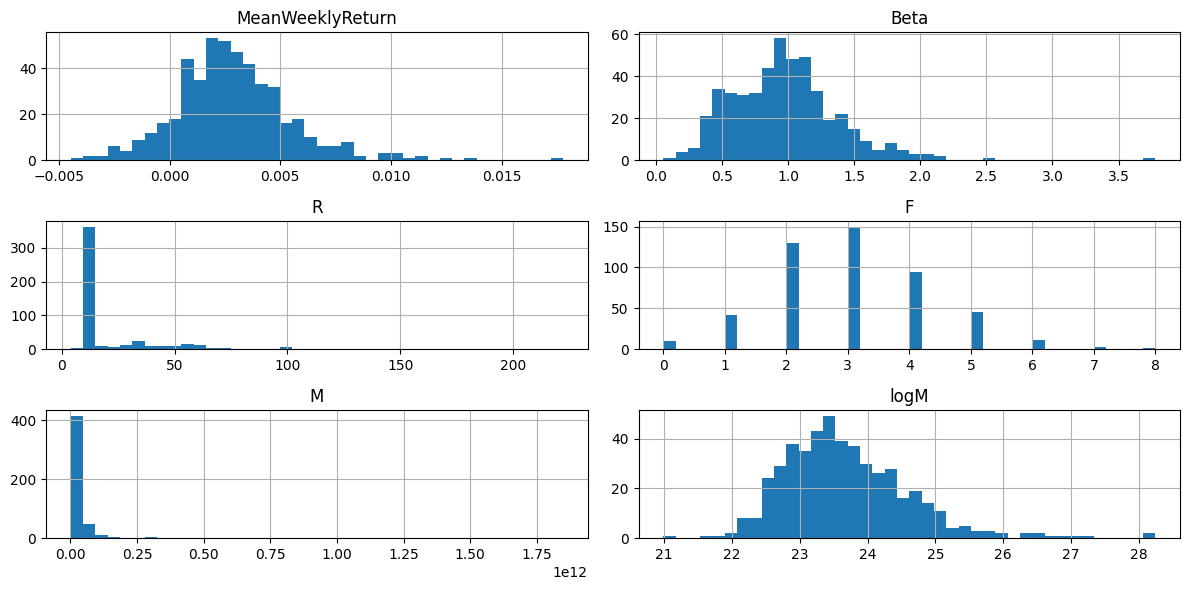

RR_Ward: k = 2, sizes [92, 394], silhouette 0.339
RR_KM: k = 2, sizes [143, 343], silhouette 0.387
RFM_Ward: k = 2, sizes [82, 404], silhouette 0.368
RFM_KM: k = 2, sizes [418, 68], silhouette 0.423


In [9]:
from scipy.stats import skew
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
SEED = 42

# two separate feature matrices on the SAME shares
rr  = feat[["MeanWeeklyReturn", "Beta"]].copy()
rfm_df = feat[["R", "F"]].assign(logM=np.log1p(feat.M))
assert rr.index.equals(rfm_df.index) and rr.notna().all().all() and rfm_df.notna().all().all()

# inspect skew and outliers (raw features, then log1p(M))
def iqr_out(s): q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
cols = feat[["MeanWeeklyReturn", "Beta", "R", "F", "M", "logM"]]
insp = pd.DataFrame({"skew": cols.apply(skew), "n |z|>3": ((cols - cols.mean()).abs() / cols.std() > 3).sum(), "n IQR outliers": cols.apply(iqr_out)})
print(insp.round(2))
cols.hist(bins=40, figsize=(12, 6)); plt.tight_layout(); plt.savefig("outputs/feature_distributions.png", dpi=150); plt.show()

# standardise each matrix separately (mean 0, sd 1); R and F kept untransformed, outliers retained
X_rr  = pd.DataFrame(StandardScaler().fit_transform(rr),     index=rr.index,     columns=rr.columns)
X_rfm = pd.DataFrame(StandardScaler().fit_transform(rfm_df), index=rfm_df.index, columns=rfm_df.columns)
assert np.allclose(X_rr.mean(), 0) and np.allclose(X_rfm.std(ddof=0), 1)

# four baseline solutions: Ward and K-means on each matrix
def pick_k(fit, X):
    best = None
    for k in range(2, 9):
        lab = fit(k); n = np.bincount(lab)
        sil = silhouette_score(X, lab)
        if n.min() >= max(5, 0.05 * len(X)) and (best is None or sil > best[1]): best = (k, sil)
    return best[0]
ward = lambda X: (lambda k: fcluster(linkage(X, "ward"), k, "maxclust") - 1)
kmns = lambda X: (lambda k: KMeans(k, n_init=50, random_state=SEED).fit_predict(X))
for name, X in [("RR", X_rr), ("RFM", X_rfm)]:
    for alg, f in [("Ward", ward), ("KM", kmns)]:
        k = pick_k(f(X), X); feat[f"{name}_{alg}"] = f(X)(k) + 1
        print(f"{name}_{alg}: k = {k}, sizes {np.bincount(feat[f'{name}_{alg}'])[1:].tolist()}, silhouette {silhouette_score(X, feat[f'{name}_{alg}']):.3f}")
feat.to_csv("outputs/feature_table_with_clusters.csv")

**2.2 Agglomerative clustering**

Ward RR: silhouette and sizes
 k  silhouette  min_size                            sizes
 2       0.339        92                        [92, 394]
 3       0.274        92                   [92, 164, 230]
 4       0.282        48               [92, 164, 48, 182]
 5       0.304        48            [92, 66, 98, 48, 182]
 6       0.320         5         [5, 87, 66, 98, 48, 182]
 7       0.324         5     [5, 87, 66, 98, 48, 22, 160]
 8       0.321         5 [5, 56, 31, 66, 98, 48, 22, 160]
Ward RFM: silhouette and sizes
 k  silhouette  min_size                             sizes
 2       0.368        82                         [82, 404]
 3       0.304        82                    [82, 154, 250]
 4       0.289        43                [82, 154, 43, 207]
 5       0.305        10            [72, 10, 154, 43, 207]
 6       0.314        10        [72, 10, 18, 136, 43, 207]
 7       0.292        10    [72, 10, 18, 136, 43, 66, 141]
 8       0.302        10 [72, 10, 18, 57, 79, 43, 66, 141]

Wa

,k,cluster,Return_pct,Beta,n
0,2,1,0.55,1.22,92
1,2,2,0.21,0.88,394
2,3,1,0.55,1.22,92
3,3,2,0.33,0.58,164
4,3,3,0.17,1.04,230
5,4,1,0.55,1.22,92
6,4,2,0.33,0.58,164
7,4,3,0.25,1.51,48
8,4,4,0.17,0.96,182
9,5,1,0.55,1.22,92



Ward RFM: median profile by k (original units; R, F in days, M in USD bn, return in %)


,k,cluster,R,F,M_bn,n
0,2,1,54.5,2.0,17.85,82
1,2,2,11.0,3.0,16.05,404
2,3,1,54.5,2.0,17.85,82
3,3,2,11.0,3.0,39.70,154
4,3,3,11.0,3.0,11.18,250
5,4,1,54.5,2.0,17.85,82
6,4,2,11.0,3.0,39.70,154
7,4,3,11.0,5.0,14.43,43
8,4,4,11.0,3.0,10.79,207
9,5,1,53.0,2.0,17.68,72



Selected k (Ward): {'RR': 2, 'RFM': 2}


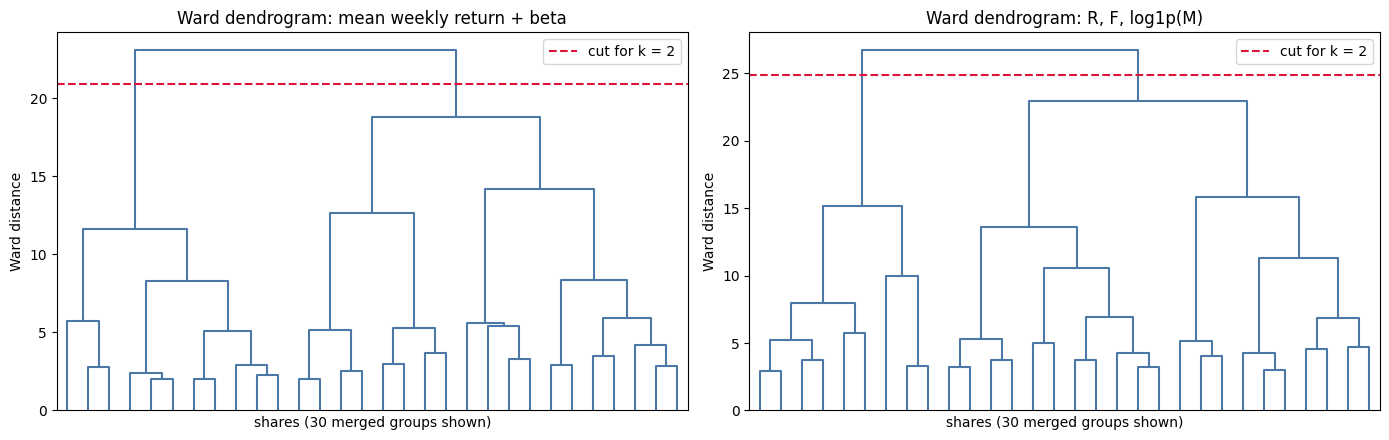

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
feat["Return_pct"], feat["M_bn"] = feat.MeanWeeklyReturn * 100, feat.M / 1e9
Z  = {"RR": linkage(X_rr, "ward", "euclidean"), "RFM": linkage(X_rfm, "ward", "euclidean")}
XS = {"RR": X_rr, "RFM": X_rfm}
PROFILE_COLS = {"RR": ["Return_pct", "Beta"], "RFM": ["R", "F", "M_bn"]} # medians, original units

def diagnose(lab_fn, X): # silhouette and sizes for k = 2..8
    rows = []
    for k in range(2, 9):
        lab = lab_fn(k); n = np.bincount(lab)
        rows.append(dict(k=k, silhouette=round(silhouette_score(X, lab), 3), min_size=n.min(), sizes=n.tolist()))
    return pd.DataFrame(rows)
def choose_k(d):
    ok = d[d.min_size >= max(5, 0.05 * len(feat))]
    return int(ok.loc[ok.silhouette.idxmax(), "k"]) if len(ok) else int(d.loc[d.silhouette.idxmax(), "k"])

# silhouette and sizes for k
ward_diag = {m: diagnose(lambda k, m=m: fcluster(Z[m], k, "maxclust") - 1, XS[m]) for m in Z}
for m in Z: print(f"Ward {m}: silhouette and sizes"); print(ward_diag[m].to_string(index=False))

# interpretable profiles for EVERY k: median of each feature in original units, plus cluster size
prof = {}
for m in Z:
    rows = []
    for k in range(2, 9):
        lab = fcluster(Z[m], k, "maxclust")
        g = feat.groupby(lab)[PROFILE_COLS[m]].median().round(2)
        g["n"] = pd.Series(lab).value_counts().sort_index().values
        g.insert(0, "cluster", g.index); g.insert(0, "k", k); rows.append(g)
    prof[m] = pd.concat(rows, ignore_index=True)
    prof[m].to_csv(f"outputs/ward_profiles_by_k_{m}.csv", index=False)
    print(f"\nWard {m}: median profile by k (original units; R, F in days, M in USD bn, return in %)"); display(prof[m])

K_WARD = {m: choose_k(ward_diag[m]) for m in Z}
# K_WARD = {"RR": 3, "RFM": 3}
print("\nSelected k (Ward):", K_WARD)

# one dendrogram per matrix, with the chosen cut marked
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, m, ttl in [(ax[0], "RR", "Ward dendrogram: mean weekly return + beta"), (ax[1], "RFM", "Ward dendrogram: R, F, log1p(M)")]:
    dendrogram(Z[m], truncate_mode="lastp", p=30, no_labels=True, color_threshold=0, above_threshold_color="#4C78A8", ax=a)
    k = K_WARD[m]; a.axhline((Z[m][-(k - 1), 2] + Z[m][-k, 2]) / 2, color="crimson", ls="--", label=f"cut for k = {k}")
    a.set_title(ttl); a.set_xlabel("shares (30 merged groups shown)"); a.set_ylabel("Ward distance"); a.legend()
plt.tight_layout(); plt.savefig("outputs/dendrograms.png", dpi=150); plt.show()

**2.3 K means clustering**

K-means RR
 k  inertia  silhouette  min_size                            sizes  seed_ARI
 2    621.6       0.387       143                       [143, 343]     1.000
 3    461.2       0.329       119                  [202, 165, 119]     1.000
 4    371.6       0.327        40              [132, 154, 40, 160]     1.000
 5    309.6       0.341        27          [112, 166, 131, 27, 50]     0.669
 6    265.1       0.335         5       [156, 127, 50, 105, 43, 5]     0.645
 7    227.2       0.328         5    [103, 85, 41, 128, 77, 47, 5]     0.876
 8    194.4       0.354         5 [136, 43, 76, 78, 5, 29, 40, 79]     0.908
K-means RFM
 k  inertia  silhouette  min_size                             sizes  seed_ARI
 2   1066.8       0.423        68                         [418, 68]     1.000
 3    796.6       0.325        64                    [270, 152, 64]     0.991
 4    609.8       0.341        61                [122, 61, 212, 91]     0.994
 5    514.7       0.358        11            [68,

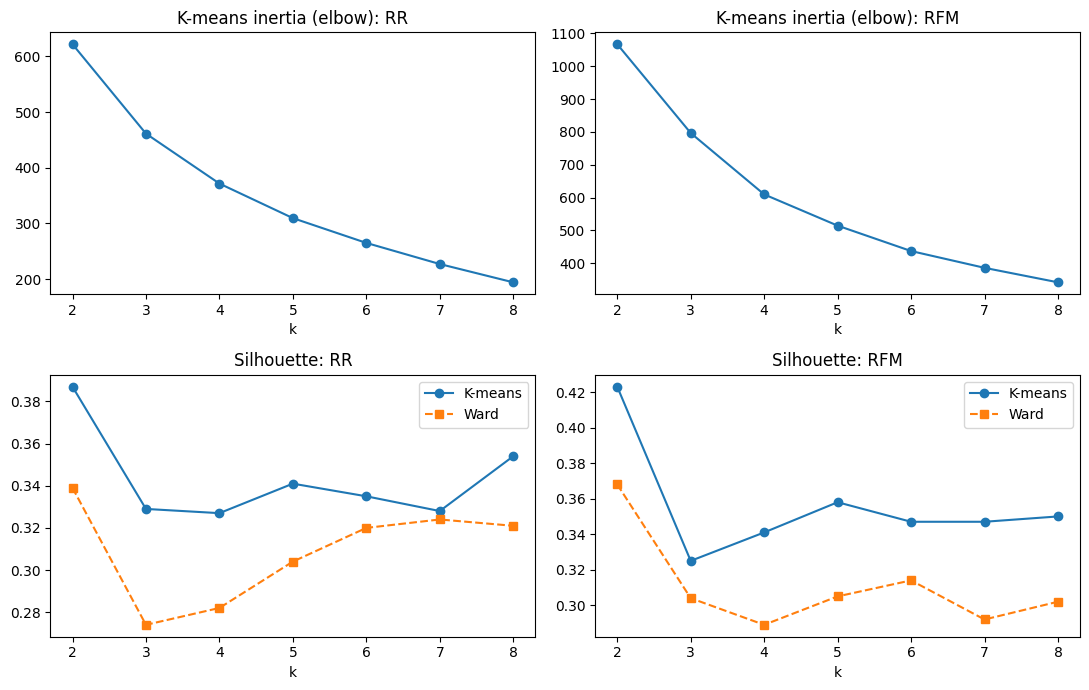

In [11]:
from sklearn.metrics import adjusted_rand_score
def km_diag(X):
    rows = []
    for k in range(2, 9):
        km = KMeans(k, n_init=50, random_state=SEED).fit(X); n = np.bincount(km.labels_)
        alt = [KMeans(k, n_init=10, random_state=s).fit_predict(X) for s in (1, 2, 3)]          # initialisation stability
        rows.append(dict(k=k, inertia=round(km.inertia_, 1), silhouette=round(silhouette_score(X, km.labels_), 3),
                         min_size=n.min(), sizes=n.tolist(), seed_ARI=round(np.mean([adjusted_rand_score(km.labels_, a) for a in alt]), 3)))
    return pd.DataFrame(rows)
km_d = {m: km_diag(XS[m]) for m in XS}
for m in km_d: print(f"K-means {m}"); print(km_d[m].to_string(index=False))
K_KM = {m: choose_k(km_d[m]) for m in km_d}
# K_KM = {"RR": 4, "RFM": 3}
print("Selected k (K-means):", K_KM)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for j, m in enumerate(["RR", "RFM"]):
    ax[0, j].plot(km_d[m].k, km_d[m].inertia, "o-"); ax[0, j].set_title(f"K-means inertia (elbow): {m}"); ax[0, j].set_xlabel("k")
    ax[1, j].plot(km_d[m].k, km_d[m].silhouette, "o-", label="K-means"); ax[1, j].plot(ward_diag[m].k, ward_diag[m].silhouette, "s--", label="Ward")
    ax[1, j].set_title(f"Silhouette: {m}"); ax[1, j].set_xlabel("k"); ax[1, j].legend()
plt.tight_layout(); plt.savefig("outputs/k_selection.png", dpi=150); plt.show()

**2.4 Cluster profiles and algorithm comparison**


RR_Ward (return in %, beta)


,Return_pct_mean,Return_pct_median,Beta_mean,Beta_median,n
RR_Ward,,,,,
1,0.20,0.21,0.9,0.88,394
2,0.63,0.55,1.3,1.22,92



RR_KM (return in %, beta)


,Return_pct_mean,Return_pct_median,Beta_mean,Beta_median,n
RR_KM,,,,,
1,0.18,0.19,0.82,0.83,343
2,0.53,0.49,1.35,1.28,143



RFM_Ward (R, F in days, M in USD bn)


,R_mean,R_median,F_mean,F_median,M_bn_mean,M_bn_median,n
RFM_Ward,,,,,,,
1,12.72,11.0,3.17,3.0,37.83,16.05,404
2,58.30,54.5,2.10,2.0,47.16,17.85,82



RFM_KM (R, F in days, M in USD bn)


,R_mean,R_median,F_mean,F_median,M_bn_mean,M_bn_median,n
RFM_KM,,,,,,,
1,13.42,11.0,3.19,3.0,32.69,15.57,418
2,63.34,55.0,1.78,2.0,80.67,22.25,68


PCA variance explained: [0.458 0.336] | loadings (R, F, logM): [[0.71, -0.65, 0.27], [0.02, 0.4, 0.92]]


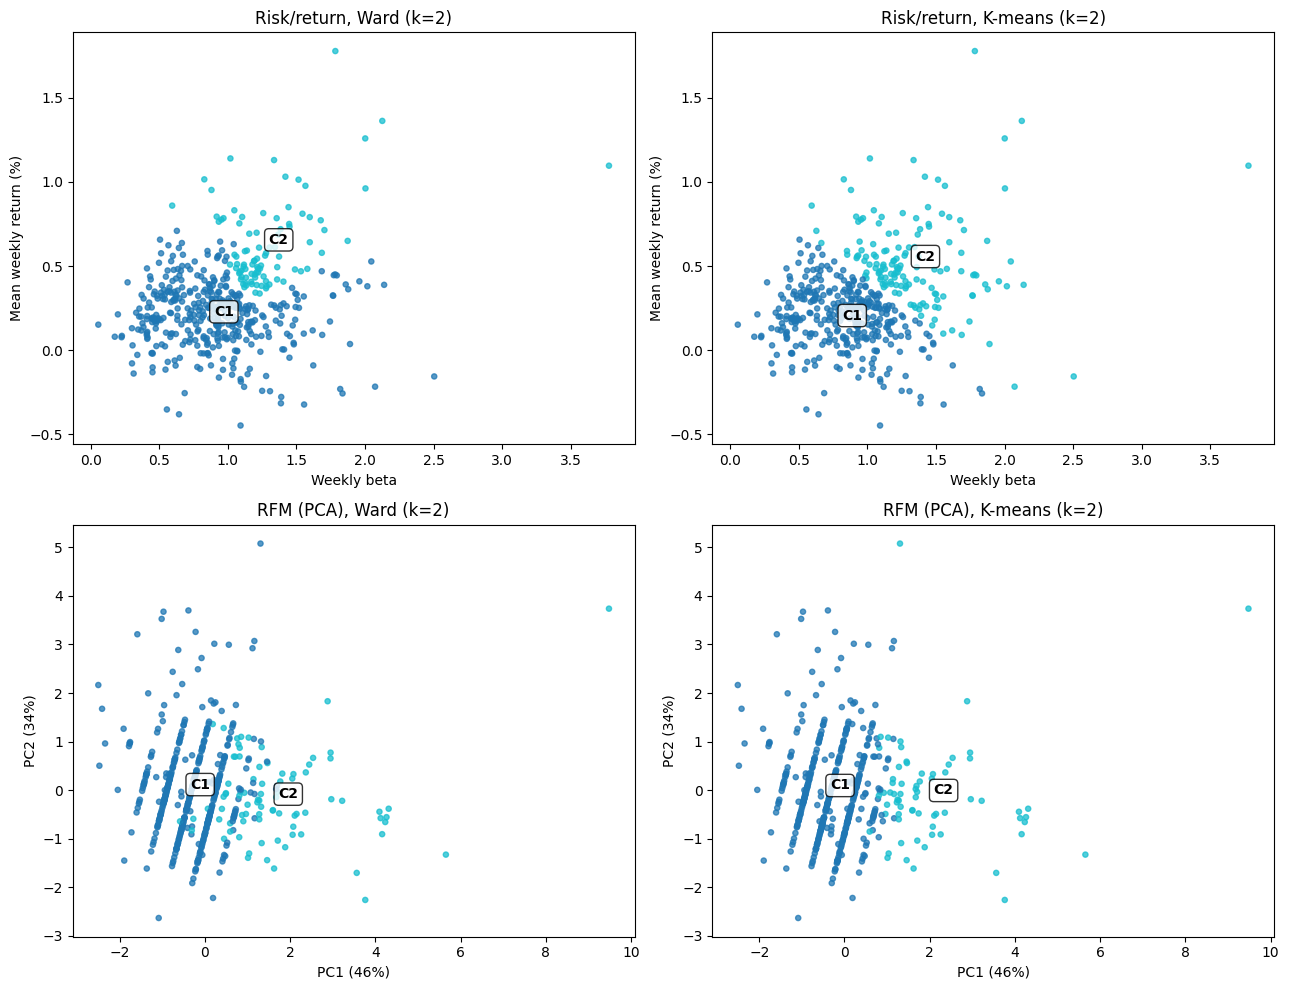

ARI Ward vs K-means | risk/return: 0.598 | RFM: 0.7


RR K-means,1,2
RR Ward,,
1,343,51
2,0,92


RFM K-means,1,2
RFM Ward,,
1,396,8
2,22,60


In [12]:
from sklearn.decomposition import PCA
def relabel(lab, key):                         # number clusters 1..k by ascending mean of key
    order = pd.Series(np.asarray(key)).groupby(lab).mean().sort_values().index
    return pd.Series(lab).map({o: i + 1 for i, o in enumerate(order)}).values
feat["RR_Ward"]  = relabel(fcluster(Z["RR"],  K_WARD["RR"],  "maxclust") - 1, feat.Beta)
feat["RR_KM"]    = relabel(KMeans(K_KM["RR"],  n_init=50, random_state=SEED).fit_predict(X_rr),  feat.Beta)
feat["RFM_Ward"] = relabel(fcluster(Z["RFM"], K_WARD["RFM"], "maxclust") - 1, feat.logM)
feat["RFM_KM"]   = relabel(KMeans(K_KM["RFM"], n_init=50, random_state=SEED).fit_predict(X_rfm), feat.logM)
feat["Return_pct"], feat["M_bn"] = feat.MeanWeeklyReturn * 100, feat.M / 1e9

def profile(col, cols):                        # mean and median in ORIGINAL units, plus cluster size
    g = feat.groupby(col)[cols].agg(["mean", "median"]); g.columns = [f"{a}_{b}" for a, b in g.columns]
    return g.join(feat.groupby(col).size().rename("n")).round(2)
for col in ["RR_Ward", "RR_KM"]:   print(f"\n{col} (return in %, beta)");     display(profile(col, ["Return_pct", "Beta"]))
for col in ["RFM_Ward", "RFM_KM"]: print(f"\n{col} (R, F in days, M in USD bn)"); display(profile(col, ["R", "F", "M_bn"]))

# 2D plots: risk/return plotted directly, RFM via PCA (visual aid only, 3 standardised features -> 2 components)
pca = PCA(2, random_state=SEED).fit(X_rfm); P = pca.transform(X_rfm)
print("PCA variance explained:", pca.explained_variance_ratio_.round(3), "| loadings (R, F, logM):", pca.components_.round(2).tolist())
def scat(ax, x, y, lab, xl, yl, ttl):
    ax.scatter(x, y, c=lab, cmap="tab10", s=14, alpha=.75)
    for c in np.unique(lab): ax.annotate(f"C{c}", (x[lab == c].mean(), y[lab == c].mean()), weight="bold", bbox=dict(boxstyle="round", fc="white", alpha=.8))
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(ttl)
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for a, col, nm in [(ax[0, 0], "RR_Ward", "Ward"), (ax[0, 1], "RR_KM", "K-means")]:
    scat(a, feat.Beta.values, feat.Return_pct.values, feat[col].values, "Weekly beta", "Mean weekly return (%)", f"Risk/return, {nm} (k={feat[col].nunique()})")
for a, col, nm in [(ax[1, 0], "RFM_Ward", "Ward"), (ax[1, 1], "RFM_KM", "K-means")]:
    scat(a, P[:, 0], P[:, 1], feat[col].values, f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", f"RFM (PCA), {nm} (k={feat[col].nunique()})")
plt.tight_layout(); plt.savefig("outputs/cluster_scatter.png", dpi=150); plt.show()

# algorithm comparison on the same shares
print("ARI Ward vs K-means | risk/return:", round(adjusted_rand_score(feat.RR_Ward, feat.RR_KM), 3), "| RFM:", round(adjusted_rand_score(feat.RFM_Ward, feat.RFM_KM), 3))
display(pd.crosstab(feat.RR_Ward, feat.RR_KM, rownames=["RR Ward"], colnames=["RR K-means"]))
display(pd.crosstab(feat.RFM_Ward, feat.RFM_KM, rownames=["RFM Ward"], colnames=["RFM K-means"]))

**2.5 RFM sensitivity and correlated inputs**

Pearson:


,R,F,logM
R,1.000,-0.346,0.152
F,-0.346,1.000,0.013
logM,0.152,0.013,1.000


Spearman:


,R,F,logM
R,1.000,-0.196,0.137
F,-0.196,1.000,-0.048
logM,0.137,-0.048,1.000


Variance share of PC1, PC2, PC3 (standardised R, F, logM): [0.458 0.336 0.206] | PC1 would be about 0.333 if the features were uncorrelated


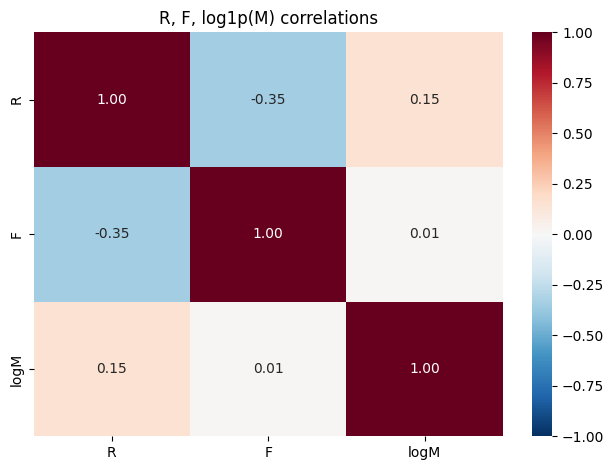

In [13]:
# 2.5.1 Correlations among R, F and log1p(M)
import seaborn as sns
pear, spear = feat[["R", "F", "logM"]].corr(), feat[["R", "F", "logM"]].corr(method="spearman")
print("Pearson:"); display(pear.round(3)); print("Spearman:"); display(spear.round(3))
ev = PCA().fit(X_rfm).explained_variance_ratio_
print("Variance share of PC1, PC2, PC3 (standardised R, F, logM):", ev.round(3), "| PC1 would be about 0.333 if the features were uncorrelated")
sns.heatmap(pear, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1); plt.title("R, F, log1p(M) correlations"); plt.tight_layout()
plt.savefig("outputs/rfm_correlations.png", dpi=150); plt.show()

In [14]:
# 2.5.2 Remove Monetary: Ward on R and F only (same shares, same k, fresh standardisation)
from scipy.stats import spearmanr
k_sel = K_WARD["RFM"]
X_rf = StandardScaler().fit_transform(feat[["R", "F"]])
feat["RF_Ward"] = relabel(fcluster(linkage(X_rf, "ward"), k_sel, "maxclust") - 1, feat.F)
print(f"k = {k_sel} | shares = {len(feat)} | ARI full RFM vs R,F only: {adjusted_rand_score(feat.RFM_Ward, feat.RF_Ward):.3f}")
display(pd.crosstab(feat.RFM_Ward, feat.RF_Ward, rownames=["Full RFM"], colnames=["R,F only"]))
for col in ["RFM_Ward", "RF_Ward"]:
    print(f"\n{col}: traded value (USD bn) and activity by cluster")
    display(feat.groupby(col).agg(n=("M", "size"), R_median=("R", "median"), F_median=("F", "median"),
                                  M_median_bn=("M_bn", "median"), M_min_bn=("M_bn", "min"), M_max_bn=("M_bn", "max")).round(2))
def eta2(v, lab): return 1 - sum(((v[lab == c] - v[lab == c].mean()) ** 2).sum() for c in np.unique(lab)) / ((v - v.mean()) ** 2).sum()
print("Share of log1p(M) variance explained by cluster membership: full RFM =", round(eta2(feat.logM.values, feat.RFM_Ward.values), 3),
      "| R,F only =", round(eta2(feat.logM.values, feat.RF_Ward.values), 3))
print("Spearman(M, F) =", round(spearmanr(feat.M, feat.F)[0], 3), "| Spearman(M, R) =", round(spearmanr(feat.M, feat.R)[0], 3))
feat.to_csv("outputs/feature_table_with_clusters.csv")

k = 2 | shares = 486 | ARI full RFM vs R,F only: 0.873


"R,F only",1,2
Full RFM,,
1,10,394
2,79,3



RFM_Ward: traded value (USD bn) and activity by cluster


,n,R_median,F_median,M_median_bn,M_min_bn,M_max_bn
RFM_Ward,,,,,,
1,404,11.0,3.0,16.05,1.30,1847.70
2,82,54.5,2.0,17.85,4.37,1825.34



RF_Ward: traded value (USD bn) and activity by cluster


,n,R_median,F_median,M_median_bn,M_min_bn,M_max_bn
RF_Ward,,,,,,
1,89,54.0,2.0,20.85,4.37,1825.34
2,397,11.0,3.0,15.46,1.30,1847.70


Share of log1p(M) variance explained by cluster membership: full RFM = 0.001 | R,F only = 0.004
Spearman(M, F) = -0.048 | Spearman(M, R) = 0.137


# **Task 3 Business Intelligence and Critical Review**

**3.1 Data mart design**

In [15]:
import datetime as dt, platform
cons = pd.read_csv("data/sp500_constituents.csv")
RUN_ID = f"v1.0_{OBS_DATE.date()}"
long = lambda df, name: df.rename_axis("date").reset_index().melt("date", var_name="ticker", value_name=name)

# 3.1.1 Grain, facts and dimensions
dim_date = pd.DataFrame({"date": adj.index})
dim_date["week_ending"] = dim_date.date + pd.to_timedelta((4 - dim_date.date.dt.weekday) % 7, unit="D")   # Friday of that week
dim_date["month"] = dim_date.date.dt.to_period("M").astype(str)
dim_date["quarter"] = dim_date.date.dt.to_period("Q").astype(str)
dim_share = cons.rename(columns={"GICS Sector": "sector", "GICS Sub-Industry": "sub_industry", "Date added": "date_added"})[
    ["Ticker", "Security", "sector", "sub_industry", "date_added"]]
dim_benchmark = pd.DataFrame({"ticker": [BENCH], "name": ["S&P 500 index"], "type": ["price index (no dividends)"]})

# 3.1.2 Provenance and calculation history
dim_run = pd.DataFrame([dict(run_id=RUN_ID, calc_version="v1.0",
    run_utc=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    source="Wikipedia constituents + yfinance",
    constituents_retrieved=str(cons.get("retrieval_date", pd.Series(["unknown"])).iloc[0]),
    study_start=START, study_end_exclusive=END, observation_date=str(OBS_DATE.date()),
    baseline_sessions=20, window_sessions=60, volume_multiple=2.0, seed=SEED,
    python=platform.python_version(), pandas=pd.__version__)]).dropna(axis=1, how="all")

# Daily facts: grain = one share x one trading date
fact_daily = (long(adj[keep], "adj_close").merge(long(close[keep], "close"))
              .merge(long(vol[keep], "volume")).merge(long(event[keep].astype(int), "high_volume_flag")))
fact_daily["traded_value"] = fact_daily.close * fact_daily.volume

# Weekly facts: grain = one share x one ending week
fact_weekly = long(wret[keep].rename_axis("date"), "weekly_return").rename(columns={"date": "week_ending"})
fact_weekly["benchmark_return"] = fact_weekly.week_ending.map(wret[BENCH])

# Feature facts: grain = one share x one run
fact_features = feat.rename_axis("ticker").reset_index()
fact_features.insert(0, "run_id", RUN_ID)

cl_cols = [c for c in ["RR_Ward", "RR_KM", "RFM_Ward", "RFM_KM", "RF_Ward"] if c in feat.columns]
fact_cluster = (feat[cl_cols].rename_axis("ticker").reset_index().melt("ticker", var_name="solution", value_name="cluster")
                .assign(run_id=RUN_ID, k=lambda d: d.groupby("solution").cluster.transform("max")))

# Integrity checks
assert not fact_daily.duplicated(["date", "ticker"]).any() and not fact_weekly.duplicated(["week_ending", "ticker"]).any()
assert set(fact_daily.ticker) <= set(dim_share.Ticker) and not fact_features.duplicated(["run_id", "ticker"]).any()

for n, d in [("dim_date", dim_date), ("dim_share", dim_share), ("dim_benchmark", dim_benchmark), ("dim_run", dim_run),
             ("fact_daily_price", fact_daily), ("fact_weekly_return", fact_weekly),
             ("fact_features", fact_features), ("fact_cluster", fact_cluster)]:
    print(f"{n:20s} rows: {len(d):>8,}")

# 3.1.3 Analytical and stakeholder support
ex = (fact_features[fact_features.run_id == RUN_ID]
      .merge(dim_share, left_on="ticker", right_on="Ticker")
      .groupby("sector").agg(shares=("ticker", "size"), avg_high_volume_days=("F", "mean"), avg_traded_value_bn=("M", lambda s: s.mean() / 1e9))
      .round(2).sort_values("avg_high_volume_days", ascending=False))
display(ex)

dim_date             rows:    1,005
dim_share            rows:      503
dim_benchmark        rows:        1
dim_run              rows:        1
fact_daily_price     rows:  488,430
fact_weekly_return   rows:  100,602
fact_features        rows:      486
fact_cluster         rows:    2,430


,shares,avg_high_volume_days,avg_traded_value_bn
sector,,,
Communication Services,20,3.75,71.53
Health Care,58,3.34,29.96
Industrials,78,3.17,20.48
Real Estate,30,3.10,11.78
Information Technology,74,3.00,86.36
Consumer Staples,32,2.84,26.53
Consumer Discretionary,47,2.83,74.02
Financials,74,2.80,26.00
Utilities,30,2.77,14.21


**3.2 Review of results and visualisation**

Risk/return clusters


,n,Return_pct,Beta,R,F,M_bn
RR_Ward,,,,,,
1,394,0.21,0.88,11.0,3.0,15.33
2,92,0.55,1.22,11.0,3.0,24.18


RFM clusters


,n,R,F,M_bn,Return_pct,Beta
RFM_Ward,,,,,,
1,404,11.0,3.0,16.05,0.27,0.94
2,82,54.5,2.0,17.85,0.24,1.05


ARI risk/return vs RFM: 0.029


RFM,1,2
RR,,
1,331,63
2,73,19


Risk/return clusters : cluster minus overall (percentage points)


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RR_Ward,,,,,,,,,,,
1,-0.3,-0.5,1.5,-0.1,0.3,2.3,-1.6,-3.8,0.3,0.7,1.2
2,1.3,2.3,-6.6,0.2,-1.1,-9.8,6.8,16.3,-1.5,-2.9,-5.1


RFM clusters : cluster minus overall (percentage points)


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RFM_Ward,,,,,,,,,,,
1,-0.2,-0.3,-0.4,0.3,0.6,0.2,1.8,-1.4,-1.0,1.3,-1.0
2,0.8,1.3,2.0,-1.7,-3.0,-1.0,-8.7,6.7,5.0,-6.2,4.8


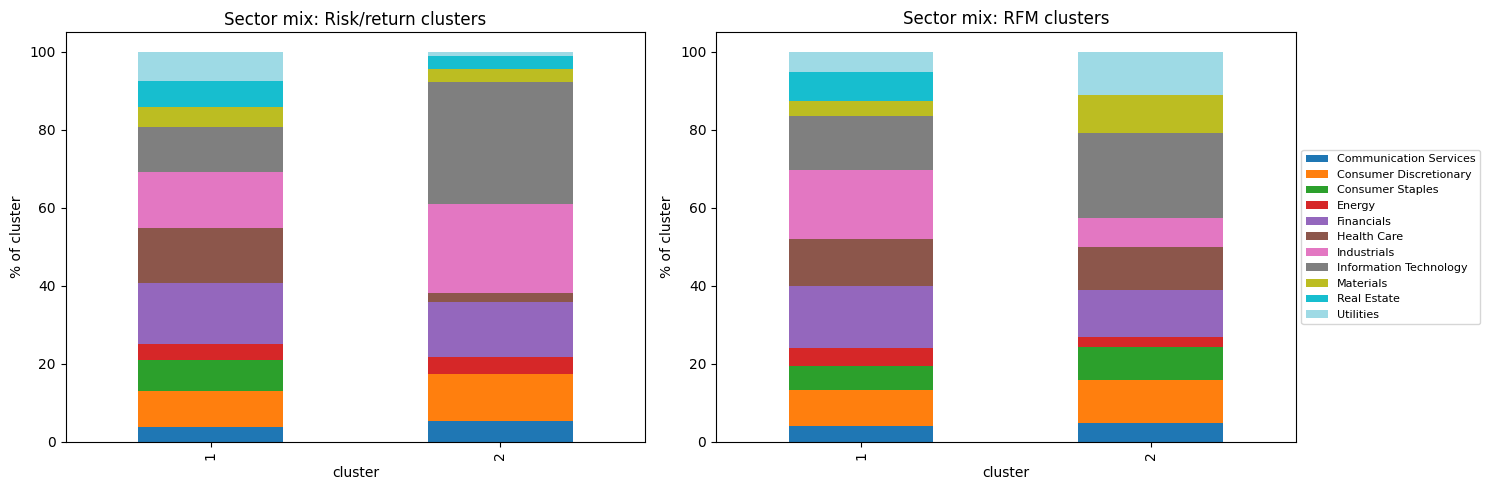

In [16]:
# 3.2.1 Cluster profiles and sector composition
feat["Sector"] = cons.set_index("Ticker")["GICS Sector"].reindex(feat.index)

# Profiles in original units (medians) for both solutions
rr = feat.groupby("RR_Ward").agg(n=("Beta", "size"), Return_pct=("Return_pct", "median"), Beta=("Beta", "median"),
                                 R=("R", "median"), F=("F", "median"), M_bn=("M_bn", "median")).round(2)
rfm = feat.groupby("RFM_Ward").agg(n=("Beta", "size"), R=("R", "median"), F=("F", "median"), M_bn=("M_bn", "median"),
                                   Return_pct=("Return_pct", "median"), Beta=("Beta", "median")).round(2)
print("Risk/return clusters"); display(rr)
print("RFM clusters"); display(rfm)
print("ARI risk/return vs RFM:", round(adjusted_rand_score(feat.RR_Ward, feat.RFM_Ward), 3))
display(pd.crosstab(feat.RR_Ward, feat.RFM_Ward, rownames=["RR"], colnames=["RFM"]))

# Sector composition of each cluster, compared with the overall sector mix
overall = feat.Sector.value_counts(normalize=True) * 100
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, col, title in [(ax[0], "RR_Ward", "Risk/return clusters"), (ax[1], "RFM_Ward", "RFM clusters")]:
    ct = pd.crosstab(feat[col], feat.Sector, normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=a, colormap="tab20", legend=False)
    a.set_title("Sector mix: " + title); a.set_xlabel("cluster"); a.set_ylabel("% of cluster")
    print(title, ": cluster minus overall (percentage points)"); display((ct - overall).round(1))
ax[1].legend(loc="center left", bbox_to_anchor=(1, .5), fontsize=8)
plt.tight_layout(); plt.savefig("outputs/sector_composition.png", dpi=150); plt.show()

In [17]:
# 3.2.2 Sensitivity findings and business uses
if "logM" not in feat: feat["logM"] = np.log1p(feat.M_bn * 1e9)

def eta2(x, g):
    x, g = np.asarray(x), np.asarray(g)
    return sum((g == k).sum() * (x[g == k].mean() - x.mean()) ** 2 for k in np.unique(g)) / ((x - x.mean()) ** 2).sum()

# correlations between the RFM inputs
print(f"R-F {feat.R.corr(feat.F):.2f} | R-logM {feat.R.corr(feat.logM):.2f} | F-logM {feat.F.corr(feat.logM):.2f}")
print(f"PC1 share of variance: {PCA().fit(X_rfm).explained_variance_ratio_[0]:.2f}")

# monetary removal comparison
print(f"ARI full RFM vs R,F only: {adjusted_rand_score(feat.RFM_Ward, feat.RF_Ward):.3f}")
print(f"eta2 of log traded value: full {eta2(feat.logM, feat.RFM_Ward):.3f} | R,F only {eta2(feat.logM, feat.RF_Ward):.3f}")

watch = feat.sort_values(["F", "R"], ascending=[False, True]).head(10)[["Sector", "R", "F", "M_bn", "RFM_Ward"]]
display(watch.round(2))

# portfolio analysis, equal-weight portfolio of each risk/return cluster
rows = []
for c in sorted(feat.RR_Ward.unique()):
    tk = feat.index[feat.RR_Ward == c]
    pr = wret[tk].mean(axis=1)
    rows.append(dict(cluster=c, shares=len(tk),
                     portfolio_beta=round(pr.cov(wret[BENCH]) / wret[BENCH].var(), 2),
                     avg_share_vol_pct=round(wret[tk].std().mean() * 100, 2),
                     portfolio_vol_pct=round(pr.std() * 100, 2),
                     avg_pairwise_corr=round((wret[tk].corr().values.sum() - len(tk)) / (len(tk) * (len(tk) - 1)), 2)))
display(pd.DataFrame(rows))

R-F -0.35 | R-logM 0.15 | F-logM 0.01
PC1 share of variance: 0.46
ARI full RFM vs R,F only: 0.873
eta2 of log traded value: full 0.001 | R,F only 0.004


,Sector,R,F,M_bn,RFM_Ward
CI,Health Care,13.0,8,37.90,1
HSY,Consumer Staples,20.0,8,22.74,1
FOXA,Communication Services,11.0,7,9.39,1
XEL,Utilities,11.0,7,15.04,1
UNH,Health Care,14.0,7,151.31,1
AJG,Financials,4.0,6,28.24,1
AMCR,Materials,11.0,6,7.69,1
AVGO,Information Technology,11.0,6,334.04,1
CTAS,Industrials,11.0,6,20.42,1
IQV,Health Care,11.0,6,19.38,1


,cluster,shares,portfolio_beta,avg_share_vol_pct,portfolio_vol_pct,avg_pairwise_corr
0,1,394,0.9,4.01,2.16,0.30
1,2,92,1.3,5.15,3.09,0.37


In [18]:
# 3.2.3 Critical evaluation and limitations
from scipy.stats import spearmanr

# Return dependence
C = wret[feat.index].corr().values
off = ~np.eye(len(C), dtype=bool)                                       # ignore the diagonal
print(f"Mean pairwise weekly-return correlation, all shares: {C[off].mean():.3f}")
for col in ["RR_Ward", "RFM_Ward"]:
    lab = feat[col].values
    same = (lab[:, None] == lab[None, :]) & off
    diff = lab[:, None] != lab[None, :]
    print(f"  {col}: within clusters {C[same].mean():.3f} | between clusters {C[diff].mean():.3f}")

# Price adjustment - shares where Close and Adj Close daily returns differ by more than 2%
gaps = ((close[feat.index].pct_change(fill_method=None) - adj[feat.index].pct_change(fill_method=None)).abs() > 0.02).any().sum()
print(f"Shares with Close vs Adj Close gaps above 2%: {gaps} (returns use Adj Close, M uses Close)")

# Survivorship bias
added = pd.to_datetime(cons["Date added"], errors="coerce")
print(f"Survivorship: {int((added > pd.Timestamp(START)).sum())} of {len(cons)} current members joined after {START}")

# Feature overlap and liquidity proxy
print(f"R-F correlation {feat.R.corr(feat.F):.2f} | Spearman(M, F) {spearmanr(feat.M, feat.F)[0]:.2f}")
print(f"RFM clusters explain {eta2(feat.logM, feat.RFM_Ward):.0%} of the variance in log traded value")

Mean pairwise weekly-return correlation, all shares: 0.300
  RR_Ward: within clusters 0.301 | between clusters 0.296
  RFM_Ward: within clusters 0.305 | between clusters 0.286
Shares with Close vs Adj Close gaps above 2%: 21 (returns use Adj Close, M uses Close)
Survivorship: 89 of 503 current members joined after 2021-01-01
R-F correlation -0.35 | Spearman(M, F) -0.05
RFM clusters explain 0% of the variance in log traded value
